# VP2 — Aprendizado de Máquina (PPGEP 2026.2) — Parte 1: CNN vs. modelos clássicos

**Datasets escolhidos:**
- **Dataset 2 — Casting Product Defect** (impulsores de bomba submersa, binário: `ok_front` / `def_front`)
- **Dataset 3 — NEU Surface Defect Database** (aço laminado a quente, 6 classes)

Para cada dataset é seguido o pipeline obrigatório da seção 2.1 do enunciado:
EDA → pré-processamento (redimensionamento, normalização, extração de features, split) →
hiperparametrização por **CV + GridSearch** e por **Optuna** (comparadas) →
treinamento de **MLP, SVM, AD, RF, NB e CNN** sobre os mesmos dados →
avaliação (Acurácia, Precisão/Recall/F1 macro, matriz de confusão, tempo de treino) → comparação.

Estrutura (seção 3.2 do enunciado):
- Seção 1 — Importações e configuração
- Seções 2–5 — Dataset 2 (Casting): EDA, pré-processamento, treinamento, avaliação
- Seções 6–9 — Dataset 3 (NEU): EDA, pré-processamento, treinamento, avaliação
- Seção 10 — Comparação cruzada
- Seção 11 — Conclusões

## Seção 1 — Importações e configuração do ambiente

In [1]:
import os, glob, time, random, warnings, json
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from skimage.feature import hog

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report)

import optuna
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

optuna.logging.set_verbosity(optuna.logging.WARNING)

# Reprodutibilidade
SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
keras.utils.set_random_seed(SEED)

# Caminhos — ajuste DATA_DIR para onde os datasets foram descompactados.
#   casting_data/{train,test}/{def_front,ok_front}/*.jpeg   (Kaggle: ravirajsinh45/real-life-industrial-dataset-of-casting-product)
#   NEU/{train,valid,test}/{Crazing,...}/*.bmp               (Kaggle: fantacher/neu-metal-surface-defects-data)
DATA_DIR = os.environ.get("VP2_DATA", "data")
CASTING_DIR = os.path.join(DATA_DIR, "casting_data")
NEU_DIR = os.path.join(DATA_DIR, "NEU")
FIG_DIR = "figuras"; os.makedirs(FIG_DIR, exist_ok=True)
MODEL_DIR = "modelos"; os.makedirs(MODEL_DIR, exist_ok=True)

# Orçamento das buscas (reduzido para rodar em CPU em tempo razoável)
CV_FOLDS = 5             # folds da validação cruzada dos modelos clássicos
N_TRIALS_CLASSIC = 25    # trials do Optuna por modelo clássico
N_TRIALS_CNN = 12        # trials do Optuna para a CNN
CNN_MAX_EPOCHS = 40
if os.environ.get("VP2_FAST"):  # modo de teste rápido do código (não usado nos resultados)
    N_TRIALS_CLASSIC, N_TRIALS_CNN, CNN_MAX_EPOCHS, CV_FOLDS = 2, 2, 2, 2

IMG_SIZE = 64            # 64x64 px para o Casting (nota do enunciado)
NEU_IMG_SIZE = 128       # 128x128 px para o NEU (textura fina; ver justificativa na Seção 7)
PCA_COMPONENTS = 100     # dimensão após PCA (faixa 50–200 recomendada na seção 3.1)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

# Cache das buscas de hiperparâmetros (as etapas mais demoradas): se o notebook for reexecutado,
# os resultados já calculados são lidos do disco. Para refazer tudo do zero: VP2_CACHE=0 ou apagar a pasta.
import pickle
CACHE_DIR = "cache"; os.makedirs(CACHE_DIR, exist_ok=True)
USE_CACHE = os.environ.get("VP2_CACHE", "1") != "0"
def cached(key, fn):
    path = os.path.join(CACHE_DIR, key + ".pkl")
    if USE_CACHE and os.path.exists(path):
        print(f"[cache] '{key}' carregado de {path}")
        with open(path, "rb") as f:
            return pickle.load(f)
    result = fn()
    with open(path, "wb") as f:
        pickle.dump(result, f)
    return result

def savefig(name):
    """Salva a figura atual em FIG_DIR (usada no relatório) e a exibe."""
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, name), dpi=130, bbox_inches="tight")
    plt.show()

print("TensorFlow", tf.__version__, "| Optuna", optuna.__version__)

I0000 00:00:1792527751.356854     258 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792527751.357417     258 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1792527753.085345     258 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792527753.086104     258 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


TensorFlow 2.21.0 | Optuna 5.0.0


### Funções auxiliares reutilizadas pelos dois datasets
Para não duplicar código, todo o pipeline é escrito como funções; as seções de cada dataset
chamam essas funções e comentam os resultados.

In [2]:
# ---------- Carregamento e EDA ----------
def load_images(paths, size=IMG_SIZE):
    """Lê as imagens, converte para escala de cinza, redimensiona para size x size
    e normaliza os pixels para [0, 1] (float32)."""
    X = np.empty((len(paths), size, size), dtype=np.float32)
    for i, p in enumerate(paths):
        im = Image.open(p).convert("L").resize((size, size), Image.BILINEAR)
        X[i] = np.asarray(im, dtype=np.float32) / 255.0
    return X

def plot_class_distribution(labels, class_names, title, fname):
    counts = pd.Series(labels).value_counts().sort_index()
    ax = sns.barplot(x=[class_names[i] for i in counts.index], y=counts.values, color="#4C72B0")
    for i, v in enumerate(counts.values):
        ax.text(i, v, f"{v}\n({v/counts.sum():.1%})", ha="center", va="bottom", fontsize=9)
    ax.set_title(title); ax.set_ylabel("nº de imagens"); ax.set_ylim(0, counts.max() * 1.2)
    plt.xticks(rotation=20)
    savefig(fname)
    return counts

def plot_samples(paths, labels, class_names, fname, n_per_class=5):
    """Mostra amostras originais (sem redimensionar) de cada classe."""
    k = len(class_names)
    fig, axes = plt.subplots(k, n_per_class, figsize=(2 * n_per_class, 2 * k))
    rng = np.random.default_rng(SEED)
    for c in range(k):
        idx = rng.choice(np.where(np.array(labels) == c)[0], n_per_class, replace=False)
        for j, i in enumerate(idx):
            axes[c, j].imshow(Image.open(paths[i]).convert("L"), cmap="gray")
            axes[c, j].axis("off")
        axes[c, 0].set_title(class_names[c], loc="left", fontsize=10)
    savefig(fname)

def plot_mean_and_hist(X, y, class_names, fname):
    """Imagem média por classe + histograma de intensidade de pixels por classe."""
    k = len(class_names)
    fig, axes = plt.subplots(1, k + 1, figsize=(2.6 * (k + 1), 2.8))
    for c in range(k):
        axes[c].imshow(X[y == c].mean(0), cmap="gray"); axes[c].axis("off")
        axes[c].set_title(f"média: {class_names[c]}", fontsize=9)
    for c in range(k):
        axes[k].hist(X[y == c].ravel()[::50], bins=50, histtype="step", density=True, label=class_names[c])
    axes[k].set_title("intensidade dos pixels", fontsize=9); axes[k].legend(fontsize=7)
    savefig(fname)

# ---------- Extração de features ----------
def hog_features(X, ppc=8, cpb=2, orientations=9):
    """HOG (Histogram of Oriented Gradients) — captura bordas e gradientes direcionais,
    recomendado na seção 3.1 para datasets de textura."""
    return np.array([hog(x, orientations=orientations, pixels_per_cell=(ppc, ppc),
                         cells_per_block=(cpb, cpb), block_norm="L2-Hys") for x in X], dtype=np.float32)

def flatten_features(X, size=32):
    """Achatamento: reduz para 32x32 e transforma em vetor de 1.024 features (seção 3.1)."""
    t = tf.image.resize(X[..., None], (size, size)).numpy()
    return t.reshape(len(X), -1)

def compare_feature_sets(feature_sets, y, cv):
    """Compara rapidamente conjuntos de features com modelos de referência (hiperparâmetros
    padrão) para justificar a escolha da representação usada pelos modelos clássicos."""
    rows = []
    for fname, F in feature_sets.items():
        for mname, clf in {"SVM (rbf)": SVC(), "RF": RandomForestClassifier(200, n_jobs=-1, random_state=SEED),
                           "NB": GaussianNB()}.items():
            pipe = Pipeline([("scaler", StandardScaler()), ("pca", PCA(PCA_COMPONENTS, random_state=SEED)), ("clf", clf)])
            s = cross_val_score(pipe, F, y, cv=cv, scoring="f1_macro", n_jobs=1)
            rows.append({"features": fname, "modelo": mname, "F1 macro (CV)": s.mean(), "desvio": s.std()})
    return pd.DataFrame(rows).pivot(index="modelo", columns="features", values="F1 macro (CV)")

def plot_pca_variance(F, fname):
    p = PCA(min(300, F.shape[1]), random_state=SEED).fit(StandardScaler().fit_transform(F))
    cum = np.cumsum(p.explained_variance_ratio_)
    plt.figure(figsize=(5, 3.2))
    plt.plot(np.arange(1, len(cum) + 1), cum)
    plt.axvline(PCA_COMPONENTS, ls="--", c="gray")
    plt.title(f"PCA sobre HOG — {cum[PCA_COMPONENTS-1]:.1%} da variância com {PCA_COMPONENTS} componentes", fontsize=9)
    plt.xlabel("nº de componentes"); plt.ylabel("variância explicada acumulada")
    savefig(fname)

In [3]:
# ---------- Modelos clássicos: espaço de busca para GridSearch e Optuna ----------
def make_pipeline(clf):
    """Padronização -> PCA -> classificador. O PCA fica DENTRO do pipeline para ser
    ajustado só nos folds de treino da CV (sem vazamento de informação)."""
    return Pipeline([("scaler", StandardScaler()),
                     ("pca", PCA(PCA_COMPONENTS, random_state=SEED)),
                     ("clf", clf)])

CLASSIC_MODELS = {
    "MLP": dict(
        est=MLPClassifier(max_iter=400, early_stopping=True, random_state=SEED),
        grid={"clf__hidden_layer_sizes": [(100,), (200,), (128, 64)],
              "clf__alpha": [1e-4, 1e-3, 1e-2],
              "clf__learning_rate_init": [1e-3, 3e-3]},
        optuna=lambda t: {"clf__hidden_layer_sizes": [(64,), (100,), (200,), (128, 64), (256, 128)][
                              t.suggest_int("arch", 0, 4)],
                          "clf__alpha": t.suggest_float("alpha", 1e-5, 1e-1, log=True),
                          "clf__learning_rate_init": t.suggest_float("lr", 1e-4, 1e-2, log=True)}),
    "SVM": dict(
        est=SVC(kernel="rbf", random_state=SEED),
        grid={"clf__C": [0.1, 1, 10, 100], "clf__gamma": ["scale", 1e-3, 1e-2]},
        optuna=lambda t: {"clf__C": t.suggest_float("C", 1e-2, 1e3, log=True),
                          "clf__gamma": t.suggest_float("gamma", 1e-4, 1e-1, log=True)}),
    "AD": dict(
        est=DecisionTreeClassifier(random_state=SEED),
        grid={"clf__max_depth": [5, 10, 20, None], "clf__min_samples_leaf": [1, 5, 10],
              "clf__criterion": ["gini", "entropy"]},
        optuna=lambda t: {"clf__max_depth": t.suggest_int("max_depth", 3, 40),
                          "clf__min_samples_leaf": t.suggest_int("min_samples_leaf", 1, 30),
                          "clf__criterion": t.suggest_categorical("criterion", ["gini", "entropy"])}),
    "RF": dict(
        est=RandomForestClassifier(n_jobs=-1, random_state=SEED),
        grid={"clf__n_estimators": [100, 300], "clf__max_depth": [10, 20, None],
              "clf__max_features": ["sqrt", 0.3]},
        optuna=lambda t: {"clf__n_estimators": t.suggest_int("n_estimators", 50, 400, step=50),
                          "clf__max_depth": t.suggest_int("max_depth", 5, 40),
                          "clf__max_features": t.suggest_float("max_features", 0.05, 0.6),
                          "clf__min_samples_leaf": t.suggest_int("min_samples_leaf", 1, 10)}),
    "NB": dict(
        est=GaussianNB(),
        grid={"clf__var_smoothing": np.logspace(-12, -2, 11)},
        optuna=lambda t: {"clf__var_smoothing": t.suggest_float("var_smoothing", 1e-12, 1e-1, log=True)}),
}

def tune_classic(F_train, y_train, cv):
    """Para cada modelo clássico roda (a) GridSearchCV e (b) Optuna (TPE) com a MESMA CV
    e a MESMA métrica (F1 macro). Retorna uma tabela comparativa e os melhores parâmetros."""
    rows, best = [], {}
    for name, spec in CLASSIC_MODELS.items():
        # (a) CV + GridSearch
        t0 = time.time()
        gs = GridSearchCV(make_pipeline(spec["est"]), spec["grid"], cv=cv, scoring="f1_macro", n_jobs=-1)
        gs.fit(F_train, y_train)
        t_gs = time.time() - t0
        n_gs = len(gs.cv_results_["params"])

        # (b) Optuna — sampler TPE, mesma CV
        def objective(trial):
            pipe = make_pipeline(spec["est"]).set_params(**spec["optuna"](trial))
            return cross_val_score(pipe, F_train, y_train, cv=cv, scoring="f1_macro", n_jobs=-1).mean()
        t0 = time.time()
        study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
        n_trials = min(N_TRIALS_CLASSIC, 12) if name == "NB" else N_TRIALS_CLASSIC
        study.optimize(objective, n_trials=n_trials)
        t_op = time.time() - t0
        op_params = spec["optuna"](optuna.trial.FixedTrial(study.best_params))

        rows.append({"modelo": name,
                     "GS: F1 CV": gs.best_score_, "GS: nº avaliações": n_gs, "GS: tempo (s)": t_gs,
                     "Optuna: F1 CV": study.best_value, "Optuna: nº trials": n_trials, "Optuna: tempo (s)": t_op})
        # Mantém a configuração vencedora entre as duas buscas
        if study.best_value > gs.best_score_:
            best[name] = ("Optuna", op_params)
        else:
            best[name] = ("GridSearch", gs.best_params_)
        print(f"{name:4s} | GS F1={gs.best_score_:.4f} ({t_gs:5.1f}s) | Optuna F1={study.best_value:.4f} ({t_op:5.1f}s)"
              f" -> usa {best[name][0]}: {best[name][1]}")
    return pd.DataFrame(rows).set_index("modelo"), best

def fit_final_classic(best, F_train, y_train, F_test):
    """Treina cada modelo com os melhores hiperparâmetros no conjunto treino+validação completo,
    medindo o tempo de treino, e prediz o conjunto de teste."""
    preds, times, models = {}, {}, {}
    for name, (_, params) in best.items():
        pipe = make_pipeline(CLASSIC_MODELS[name]["est"]).set_params(**params)
        t0 = time.time(); pipe.fit(F_train, y_train); times[name] = time.time() - t0
        preds[name] = pipe.predict(F_test); models[name] = pipe
    return preds, times, models

In [4]:
# ---------- CNN (Keras/TensorFlow) ----------
def build_cnn(input_shape, n_classes, n_filters=32, n_blocks=3, dense_units=128,
              dropout=0.3, lr=1e-3, augment=False):
    """CNN simples: blocos [Conv-BN-ReLU-Conv-BN-ReLU-MaxPool] com nº de filtros dobrando
    a cada bloco, GlobalAveragePooling (poucos parâmetros, menos overfitting), cabeça densa
    com Dropout e saída softmax."""
    inp = keras.Input(shape=input_shape)
    x = inp
    if augment:  # aumento de dados on-line (apenas no treino; desligado na inferência)
        x = layers.RandomFlip("horizontal_and_vertical")(x)
        x = layers.RandomRotation(0.1)(x)
    for b in range(n_blocks):
        f = n_filters * 2 ** b
        for _ in range(2):
            x = layers.Conv2D(f, 3, padding="same", use_bias=False)(x)
            x = layers.BatchNormalization(momentum=0.9)(x)   # momentum 0.9: médias móveis convergem em poucas épocas
            x = layers.ReLU()(x)
        x = layers.MaxPooling2D()(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(dense_units, activation="relu")(x)
    x = layers.Dropout(dropout)(x)
    out = layers.Dense(n_classes, activation="softmax")(x)
    model = keras.Model(inp, out)
    model.compile(optimizer=keras.optimizers.Adam(lr), loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    return model

def cnn_callbacks(patience=10):
    # start_from_epoch=5: nas primeiras épocas as estatísticas da BatchNorm ainda não convergiram e a
    # val_loss oscila muito; sem isso o EarlyStopping pode "restaurar" um modelo da época 1.
    return [keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True,
                                          start_from_epoch=5),
            keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-6)]

def val_f1(model, Xv, yv):
    return f1_score(yv, model.predict(Xv, verbose=0).argmax(1), average="macro")

CNN_GRID = {"n_filters": [16, 32], "lr": [1e-3, 3e-4], "dropout": [0.3, 0.5]}

def tune_cnn(Xtr, ytr, Xval, yval, n_classes, augment, epochs_search=25):
    """Busca de hiperparâmetros da CNN: (a) GridSearch em grade pequena e (b) Optuna (TPE +
    pruner Hyperband com poda por época). Para a CNN usamos validação hold-out (e não k-fold)
    por custo computacional em CPU; a métrica é o F1 macro na validação."""
    shape = Xtr.shape[1:]
    if os.environ.get("VP2_FAST"):
        epochs_search = 2
    # (a) GridSearch
    t0 = time.time(); best_gs = (-1, None)
    for nf in CNN_GRID["n_filters"]:
        for lr in CNN_GRID["lr"]:
            for dp in CNN_GRID["dropout"]:
                keras.backend.clear_session(); keras.utils.set_random_seed(SEED)
                m = build_cnn(shape, n_classes, n_filters=nf, dropout=dp, lr=lr, augment=augment)
                m.fit(Xtr, ytr, validation_data=(Xval, yval), epochs=epochs_search, batch_size=64,
                      callbacks=cnn_callbacks(8), verbose=0)
                s = val_f1(m, Xval, yval)
                if s > best_gs[0]:
                    best_gs = (s, dict(n_filters=nf, n_blocks=3, dense_units=128, dropout=dp, lr=lr))
    t_gs = time.time() - t0
    n_gs = np.prod([len(v) for v in CNN_GRID.values()])

    # (b) Optuna com TPE + Hyperband: a cada época reportamos o F1 de validação e o pruner
    # interrompe trials pouco promissores.
    class PruneCB(keras.callbacks.Callback):
        def __init__(self, trial): super().__init__(); self.trial = trial
        def on_epoch_end(self, epoch, logs=None):
            self.trial.report(val_f1(self.model, Xval, yval), epoch)
            if self.trial.should_prune():
                self.model.stop_training = True; self.pruned = True

    def objective(trial):
        p = dict(n_filters=trial.suggest_categorical("n_filters", [16, 24, 32, 48]),
                 n_blocks=trial.suggest_int("n_blocks", 2, 4),
                 dense_units=trial.suggest_categorical("dense_units", [64, 128, 256]),
                 dropout=trial.suggest_float("dropout", 0.1, 0.6),
                 lr=trial.suggest_float("lr", 1e-4, 3e-3, log=True))
        keras.backend.clear_session(); keras.utils.set_random_seed(SEED)
        m = build_cnn(shape, n_classes, augment=augment, **p)
        cb = PruneCB(trial)
        m.fit(Xtr, ytr, validation_data=(Xval, yval), epochs=epochs_search, batch_size=64,
              callbacks=cnn_callbacks(8) + [cb], verbose=0)
        if getattr(cb, "pruned", False):
            raise optuna.TrialPruned()
        return val_f1(m, Xval, yval)

    t0 = time.time()
    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED),
                                pruner=optuna.pruners.HyperbandPruner(min_resource=3, max_resource=epochs_search))
    study.optimize(objective, n_trials=N_TRIALS_CNN)
    t_op = time.time() - t0
    n_pruned = sum(t.state == optuna.trial.TrialState.PRUNED for t in study.trials)

    table = pd.DataFrame([{"modelo": "CNN", "GS: F1 CV": best_gs[0], "GS: nº avaliações": n_gs, "GS: tempo (s)": t_gs,
                           "Optuna: F1 CV": study.best_value, "Optuna: nº trials": N_TRIALS_CNN,
                           "Optuna: tempo (s)": t_op}]).set_index("modelo")
    print(f"CNN | GS F1(val)={best_gs[0]:.4f} ({t_gs:.0f}s) | Optuna F1(val)={study.best_value:.4f} "
          f"({t_op:.0f}s, {n_pruned} trials podados)")
    best = ("Optuna", study.best_params) if study.best_value > best_gs[0] else ("GridSearch", best_gs[1])
    print("Melhor configuração da CNN:", best)
    return table, best, study

def train_final_cnn(params, Xtr, ytr, Xval, yval, n_classes, augment, ckpt, patience=10):
    keras.backend.clear_session(); keras.utils.set_random_seed(SEED)
    m = build_cnn(Xtr.shape[1:], n_classes, augment=augment, **params)
    cbs = cnn_callbacks(patience) + [keras.callbacks.ModelCheckpoint(ckpt, monitor="val_loss", save_best_only=True)]
    t0 = time.time()
    h = m.fit(Xtr, ytr, validation_data=(Xval, yval), epochs=CNN_MAX_EPOCHS, batch_size=64, callbacks=cbs, verbose=0)
    t = time.time() - t0
    print(f"CNN final: {len(h.history['loss'])} épocas, {t:.1f}s, {m.count_params():,} parâmetros")
    return m, h, t

def plot_history(h, fname):
    fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
    for k, a in zip(["loss", "accuracy"], ax):
        a.plot(h.history[k], label="treino"); a.plot(h.history["val_" + k], label="validação")
        a.set_title(k); a.set_xlabel("época"); a.legend()
    savefig(fname)

# ---------- Avaliação ----------
def metrics_table(y_true, preds, times):
    rows = []
    for name, yp in preds.items():
        rows.append({"modelo": name,
                     "Acurácia": accuracy_score(y_true, yp),
                     "Precisão (macro)": precision_score(y_true, yp, average="macro", zero_division=0),
                     "Recall (macro)": recall_score(y_true, yp, average="macro", zero_division=0),
                     "F1 (macro)": f1_score(y_true, yp, average="macro"),
                     "Tempo de treino (s)": times[name]})
    return pd.DataFrame(rows).set_index("modelo")

def plot_confusions(y_true, preds, class_names, fname):
    n = len(preds); cols = 3; rows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(4.3 * cols, 3.8 * rows))
    for a, (name, yp) in zip(axes.ravel(), preds.items()):
        cm = confusion_matrix(y_true, yp)
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=a,
                    xticklabels=class_names, yticklabels=class_names)
        a.set_title(f"{name} — F1 macro {f1_score(y_true, yp, average='macro'):.3f}", fontsize=10)
        a.set_xlabel("previsto"); a.set_ylabel("real")
        a.tick_params(axis="x", rotation=30, labelsize=8); a.tick_params(axis="y", rotation=0, labelsize=8)
    for a in axes.ravel()[n:]:
        a.axis("off")
    savefig(fname)

def per_class_f1(y_true, preds, class_names):
    return pd.DataFrame({name: f1_score(y_true, yp, average=None) for name, yp in preds.items()},
                        index=class_names).T

def show_errors(X, y_true, y_pred, class_names, fname, n=8):
    idx = np.where(y_true != y_pred)[0][:n]
    if len(idx) == 0:
        print("Nenhum erro da CNN no teste."); return
    fig, axes = plt.subplots(1, len(idx), figsize=(1.9 * len(idx), 2.3))
    for a, i in zip(np.atleast_1d(axes), idx):
        a.imshow(X[i], cmap="gray"); a.axis("off")
        a.set_title(f"real: {class_names[y_true[i]]}\nprev: {class_names[y_pred[i]]}", fontsize=7)
    savefig(fname)

RESULTS = {}  # guarda as tabelas finais de cada dataset para a Seção 10

---
# DATASET 2 — Casting Product Defect
## Seção 2 — Análise exploratória (EDA)

O dataset do Kaggle já vem dividido em `train/` e `test/`, cada um com `def_front` (defeituosa)
e `ok_front` (conforme). As imagens são vistas de topo de impulsores de bomba submersa, 300×300 px,
e o autor informa que **aumento de dados já foi aplicado** (rotações/variações das mesmas peças).

Codificação: **`def_front` = 1 (classe positiva = defeito)** e `ok_front` = 0, para que os
**falsos negativos** (peça defeituosa aprovada) fiquem explícitos na matriz de confusão.

In [5]:
CAST_CLASSES = ["ok_front", "def_front"]
def list_casting(split):
    paths, labels = [], []
    for c, cname in enumerate(CAST_CLASSES):
        ps = sorted(glob.glob(os.path.join(CASTING_DIR, split, cname, "*")))
        paths += ps; labels += [c] * len(ps)
    return paths, np.array(labels)

cast_train_paths, cast_y_trainfull = list_casting("train")
cast_test_paths, cast_y_test = list_casting("test")
print(f"treino: {len(cast_train_paths)} imagens | teste: {len(cast_test_paths)} imagens")
im0 = Image.open(cast_train_paths[0])
print("resolução original:", im0.size, "| modo:", im0.mode)

cast_counts = pd.DataFrame({
    "treino": pd.Series(cast_y_trainfull).value_counts().sort_index().values,
    "teste": pd.Series(cast_y_test).value_counts().sort_index().values}, index=CAST_CLASSES)
cast_counts.loc["total"] = cast_counts.sum()
cast_counts["total"] = cast_counts.sum(axis=1)
display(cast_counts)

treino: 6633 imagens | teste: 715 imagens


resolução original: (300, 300) | modo: RGB


,treino,teste,total
ok_front,2875,262,3137
def_front,3758,453,4211
total,6633,715,7348


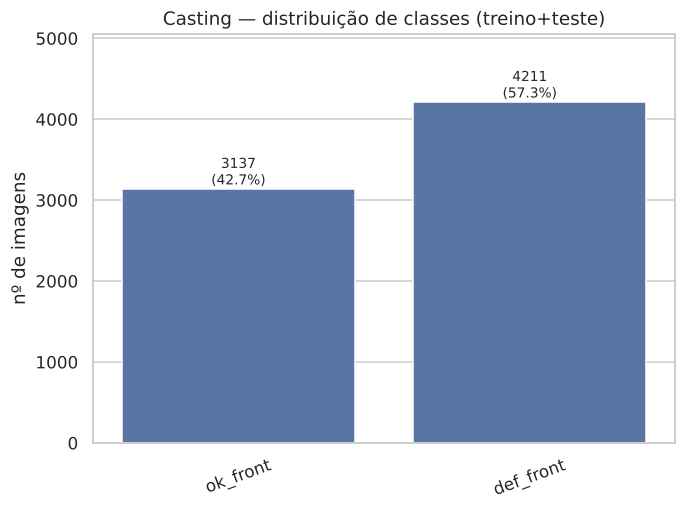

Razão def/ok no treino = 1.31 → desbalanceamento leve (≈57% / 43%).


In [6]:
plot_class_distribution(np.concatenate([cast_y_trainfull, cast_y_test]), CAST_CLASSES,
                        "Casting — distribuição de classes (treino+teste)", "cast_dist.png")
ratio = (cast_y_trainfull == 1).sum() / (cast_y_trainfull == 0).sum()
print(f"Razão def/ok no treino = {ratio:.2f} → desbalanceamento leve (≈57% / 43%).")

**Comentário:** há mais peças defeituosas que conformes (~57% vs 43%), um desbalanceamento leve.
Não é necessário reamostrar, mas por isso usamos **F1 macro** como métrica de seleção de modelos e
divisões **estratificadas**. Observação: o enunciado cita 4.511 ok / 2.837 defeituosas, mas a
contagem real dos arquivos do Kaggle é a mostrada acima (a proporção está invertida).

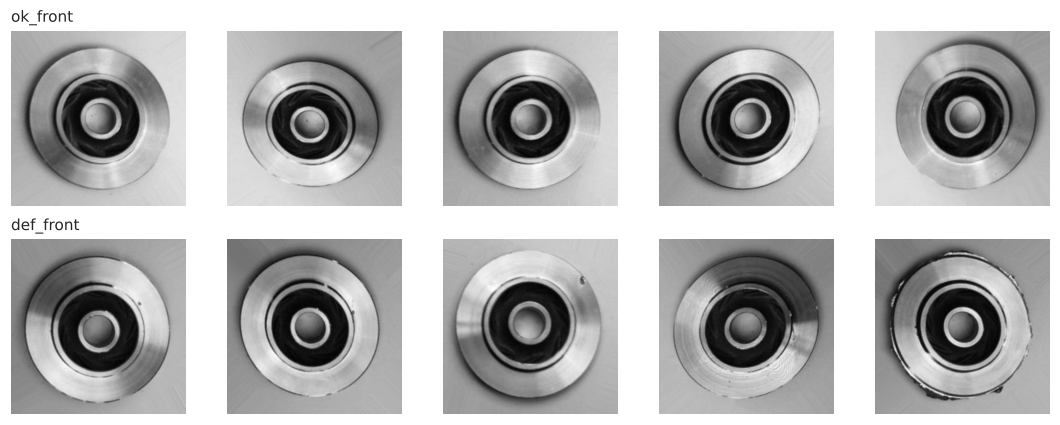

In [7]:
plot_samples(cast_train_paths, cast_y_trainfull, CAST_CLASSES, "cast_amostras.png")

As peças estão sempre centralizadas e com iluminação controlada; os defeitos (porosidade, rebarbas,
trincas na borda, falhas de preenchimento) são pequenos em relação à peça — a distinção é sutil.

Carregadas em 9.4s | treino (6633, 64, 64) | teste (715, 64, 64)


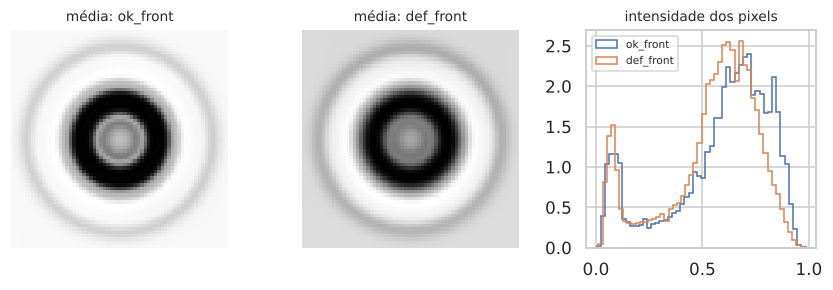

In [8]:
# Carrega todas as imagens já redimensionadas para 64x64 e normalizadas em [0,1]
t0 = time.time()
cast_X_trainfull = load_images(cast_train_paths)
cast_X_test = load_images(cast_test_paths)
print(f"Carregadas em {time.time()-t0:.1f}s | treino {cast_X_trainfull.shape} | teste {cast_X_test.shape}")
plot_mean_and_hist(cast_X_trainfull, cast_y_trainfull, CAST_CLASSES, "cast_media_hist.png")

As imagens médias das duas classes são quase idênticas (peça circular centrada), e os histogramas de
intensidade se sobrepõem: **estatísticas globais de pixels não separam as classes**; é preciso capturar
padrões locais (bordas/texturas) — o que motiva HOG para os modelos clássicos e convoluções na CNN.

## Seção 3 — Pré-processamento
1. **Redimensionamento** para 64×64 px (nota do enunciado) e conversão para escala de cinza.
2. **Normalização** dos pixels para [0, 1].
3. **Divisão**: o conjunto de teste oficial (715 imagens) é mantido intocado. O treino oficial é dividido
   em treino (85%) e validação (15%), estratificado. A validação é usada pela CNN (early stopping e busca
   de hiperparâmetros); os modelos clássicos usam treino+validação com **validação cruzada estratificada (5 folds)**.
4. **Extração de features** (modelos clássicos): HOG (8×8 px por célula, 2×2 células por bloco, 9 orientações
   → 1.764 features) → padronização → **PCA com 100 componentes**. A CNN recebe os pixels normalizados.

treino: (5638, 64, 64) | validação: (995, 64, 64) | teste: (715, 64, 64)


HOG: 1764 features/imagem (5.1s)


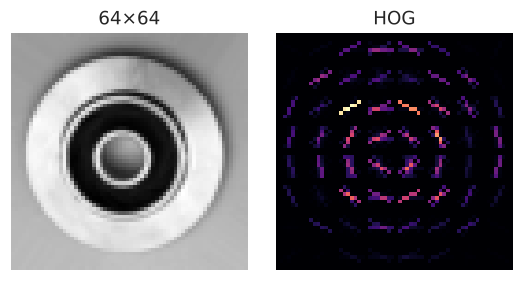

In [9]:
cast_X_tr, cast_X_val, cast_y_tr, cast_y_val = train_test_split(
    cast_X_trainfull, cast_y_trainfull, test_size=0.15, stratify=cast_y_trainfull, random_state=SEED)
print("treino:", cast_X_tr.shape, "| validação:", cast_X_val.shape, "| teste:", cast_X_test.shape)

t0 = time.time()
cast_F_trainfull = hog_features(cast_X_trainfull)
cast_F_test = hog_features(cast_X_test)
print(f"HOG: {cast_F_trainfull.shape[1]} features/imagem ({time.time()-t0:.1f}s)")

# Exemplo visual do HOG
_, hog_img = hog(cast_X_trainfull[0], orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2), visualize=True)
fig, ax = plt.subplots(1, 2, figsize=(5, 2.6))
ax[0].imshow(cast_X_trainfull[0], cmap="gray"); ax[0].set_title("64×64"); ax[0].axis("off")
ax[1].imshow(hog_img, cmap="magma"); ax[1].set_title("HOG"); ax[1].axis("off")
savefig("cast_hog_exemplo.png")

E0000 00:00:1792527771.547810     258 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


features,Flatten 32×32 + PCA,HOG + PCA
modelo,,
NB,0.8072,0.8162
RF,0.9877,0.9455
SVM (rbf),0.9752,0.9845


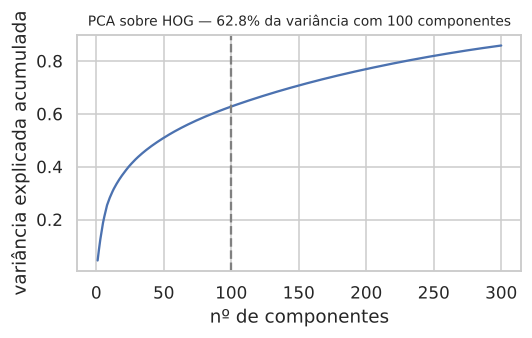

In [10]:
# Justificativa da representação: HOG+PCA vs. pixels achatados (32x32)+PCA, com modelos de referência.
cv = StratifiedKFold(CV_FOLDS, shuffle=True, random_state=SEED)
cast_feat_cmp = compare_feature_sets({"Flatten 32×32 + PCA": flatten_features(cast_X_trainfull),
                                      "HOG + PCA": cast_F_trainfull},
                                     cast_y_trainfull, StratifiedKFold(3, shuffle=True, random_state=SEED))
display(cast_feat_cmp.round(4))
plot_pca_variance(cast_F_trainfull, "cast_pca.png")

## Seção 4 — Hiperparametrização e treinamento
### 4.1 Modelos clássicos: CV + GridSearch vs. Optuna
Ambas as buscas usam a mesma CV estratificada de 5 folds e o F1 macro. O GridSearch varre uma grade fixa;
o Optuna (sampler TPE) explora um espaço contínuo/maior com um nº fixo de trials. Fica a configuração
vencedora de cada modelo.

In [11]:
cast_search_classic, cast_best_classic = cached("cast_classic", lambda: tune_classic(cast_F_trainfull, cast_y_trainfull, cv))

MLP  | GS F1=0.9804 ( 25.5s) | Optuna F1=0.9815 ( 56.7s) -> usa Optuna: {'clf__hidden_layer_sizes': (200,), 'clf__alpha': 0.01641898517884535, 'clf__learning_rate_init': 0.006586494787477355}


SVM  | GS F1=0.9905 ( 29.8s) | Optuna F1=0.9920 ( 88.8s) -> usa Optuna: {'clf__C': 552.8025189924334, 'clf__gamma': 0.0016354822490332885}


AD   | GS F1=0.8456 ( 25.8s) | Optuna F1=0.8456 ( 43.2s) -> usa GridSearch: {'clf__criterion': 'entropy', 'clf__max_depth': 20, 'clf__min_samples_leaf': 1}


RF   | GS F1=0.9545 (165.9s) | Optuna F1=0.9547 (449.4s) -> usa Optuna: {'clf__n_estimators': 350, 'clf__max_depth': 31, 'clf__max_features': 0.1548443277745072, 'clf__min_samples_leaf': 1}


NB   | GS F1=0.8219 (  7.7s) | Optuna F1=0.8219 ( 12.2s) -> usa Optuna: {'clf__var_smoothing': 6.148913105232166e-05}


### 4.2 CNN: GridSearch vs. Optuna (TPE + Hyperband)

In [12]:
cast_Xc_tr, cast_Xc_val, cast_Xc_test = cast_X_tr[..., None], cast_X_val[..., None], cast_X_test[..., None]
cast_search_cnn, cast_best_cnn, cast_study_cnn = cached("cast_cnn", lambda: tune_cnn(
    cast_Xc_tr, cast_y_tr, cast_Xc_val, cast_y_val, n_classes=2, augment=False))

CNN | GS F1(val)=0.9990 (2523s) | Optuna F1(val)=0.9990 (3445s, 4 trials podados)
Melhor configuração da CNN: ('GridSearch', {'n_filters': 16, 'n_blocks': 3, 'dense_units': 128, 'dropout': 0.5, 'lr': 0.001})


,GS: F1 CV,GS: nº avaliações,GS: tempo (s),Optuna: F1 CV,Optuna: nº trials,Optuna: tempo (s)
modelo,,,,,,
MLP,0.9804,18,25.5436,0.9815,25,56.6867
SVM,0.9905,12,29.7949,0.9920,25,88.7763
AD,0.8456,24,25.7527,0.8456,25,43.2280
RF,0.9545,12,165.8651,0.9547,25,449.4141
NB,0.8219,11,7.6903,0.8219,12,12.1979
CNN,0.9990,8,2522.6707,0.9990,12,3444.9537


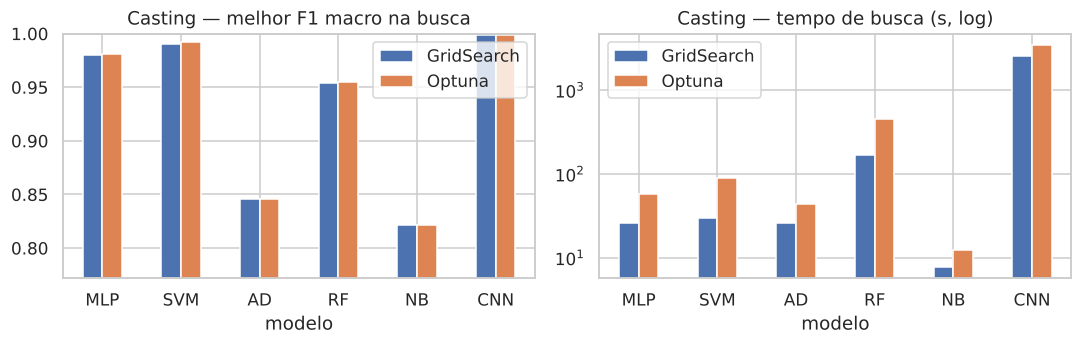

In [13]:
cast_search = pd.concat([cast_search_classic, cast_search_cnn])
display(cast_search.round(4))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.3))
cast_search[["GS: F1 CV", "Optuna: F1 CV"]].plot.bar(ax=ax[0], rot=0)
ax[0].set_ylim(max(0, cast_search[["GS: F1 CV", "Optuna: F1 CV"]].min().min() - 0.05), 1.0)
ax[0].set_title("Casting — melhor F1 macro na busca"); ax[0].legend(["GridSearch", "Optuna"])
cast_search[["GS: tempo (s)", "Optuna: tempo (s)"]].plot.bar(ax=ax[1], rot=0, logy=True)
ax[1].set_title("Casting — tempo de busca (s, log)"); ax[1].legend(["GridSearch", "Optuna"])
savefig("cast_gs_vs_optuna.png")

### 4.3 Treinamento final com os melhores hiperparâmetros
Clássicos: treinados em treino+validação (6.633 imagens). CNN: treinada no treino com early stopping
na validação (EarlyStopping + ReduceLROnPlateau + ModelCheckpoint).

CNN final: 40 épocas, 314.1s, 81,042 parâmetros


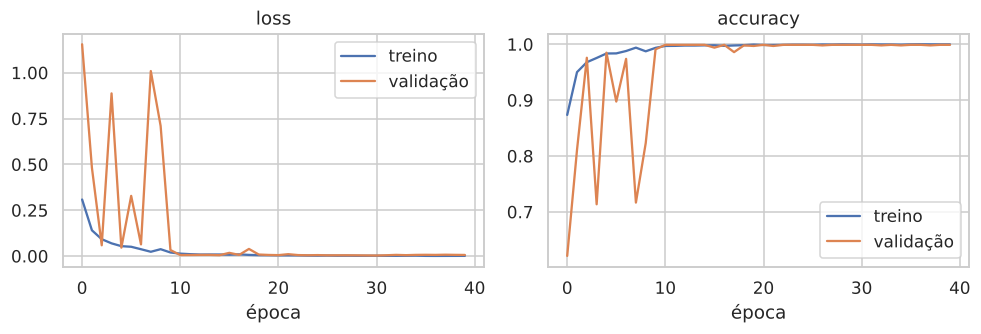

In [14]:
cast_preds, cast_times, cast_models = fit_final_classic(cast_best_classic, cast_F_trainfull, cast_y_trainfull, cast_F_test)
cast_cnn, cast_hist, cast_times["CNN"] = train_final_cnn(cast_best_cnn[1], cast_Xc_tr, cast_y_tr, cast_Xc_val, cast_y_val,
                                                         2, False, os.path.join(MODEL_DIR, "cnn_casting.keras"))
cast_preds["CNN"] = cast_cnn.predict(cast_Xc_test, verbose=0).argmax(1)
plot_history(cast_hist, "cast_cnn_curvas.png")

## Seção 5 — Avaliação no conjunto de teste (715 imagens nunca vistas)

,Acurácia,Precisão (macro),Recall (macro),F1 (macro),Tempo de treino (s)
modelo,,,,,
CNN,0.9958,0.9951,0.9959,0.9955,314.0946
SVM,0.9916,0.9895,0.9926,0.9910,2.2944
MLP,0.9818,0.9764,0.9857,0.9806,1.9899
RF,0.9734,0.9725,0.9702,0.9713,5.4906
AD,0.8615,0.8488,0.8642,0.8544,1.7905
NB,0.8448,0.8350,0.8574,0.8394,0.9793


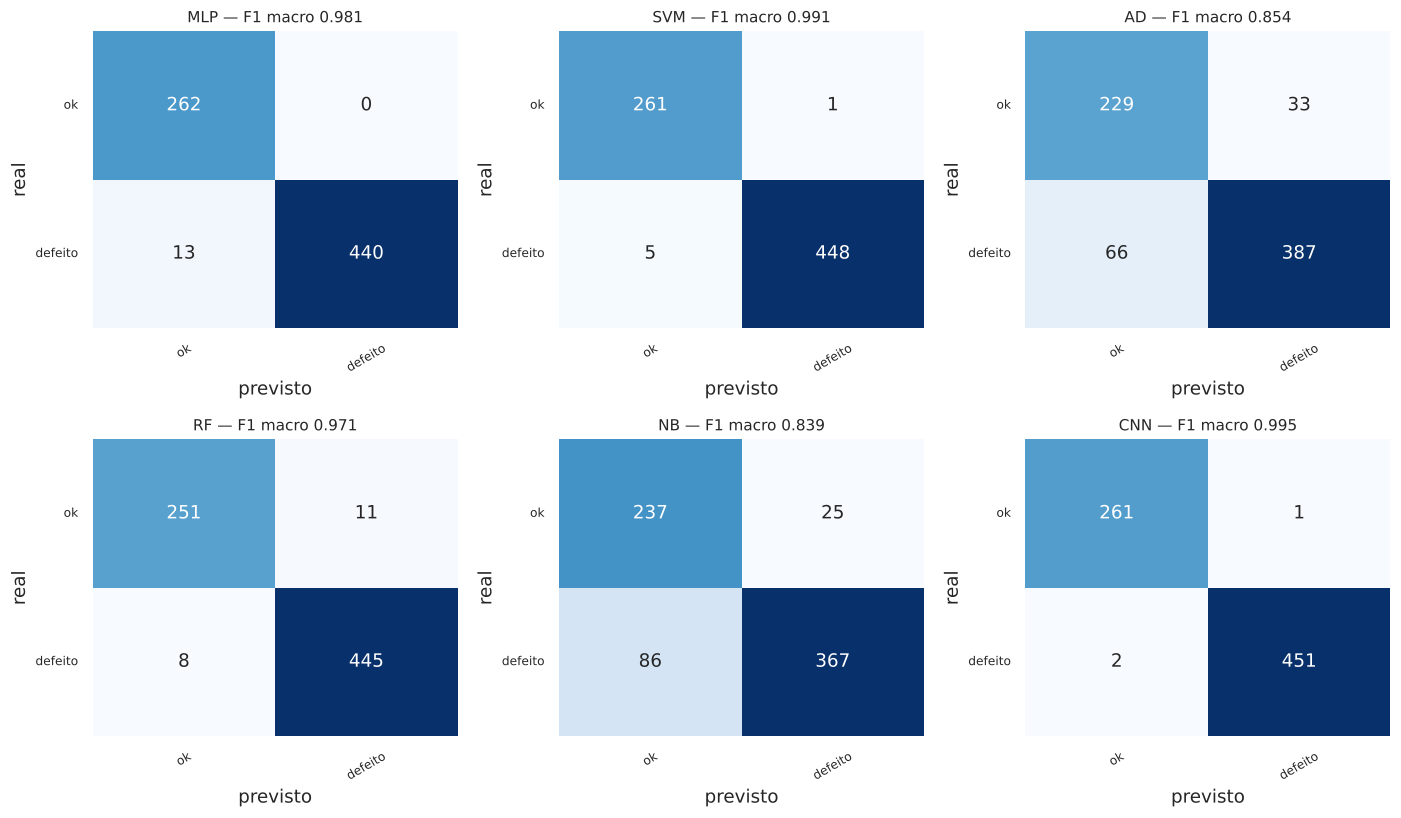

In [15]:
cast_metrics = metrics_table(cast_y_test, cast_preds, cast_times)
RESULTS["Casting"] = cast_metrics
display(cast_metrics.round(4).sort_values("F1 (macro)", ascending=False))
plot_confusions(cast_y_test, cast_preds, ["ok", "defeito"], "cast_confusao.png")

### Análise de falsos negativos (peça defeituosa aprovada)
No controle de qualidade o erro mais caro é o **falso negativo**: uma peça defeituosa que segue para o
cliente. O falso positivo (peça boa rejeitada) gera apenas retrabalho/inspeção extra.

In [16]:
fn_rows = []
for name, yp in cast_preds.items():
    tn, fp, fn, tp = confusion_matrix(cast_y_test, yp).ravel()
    fn_rows.append({"modelo": name, "FN (defeito aprovado)": fn, "FP (ok rejeitada)": fp,
                    "Recall defeito": tp / (tp + fn), "Especificidade (ok)": tn / (tn + fp)})
cast_fn = pd.DataFrame(fn_rows).set_index("modelo").sort_values("FN (defeito aprovado)")
display(cast_fn.round(4))

,FN (defeito aprovado),FP (ok rejeitada),Recall defeito,Especificidade (ok)
modelo,,,,
CNN,2,1,0.9956,0.9962
SVM,5,1,0.9890,0.9962
RF,8,11,0.9823,0.9580
MLP,13,0,0.9713,1.0000
AD,66,33,0.8543,0.8740
NB,86,25,0.8102,0.9046


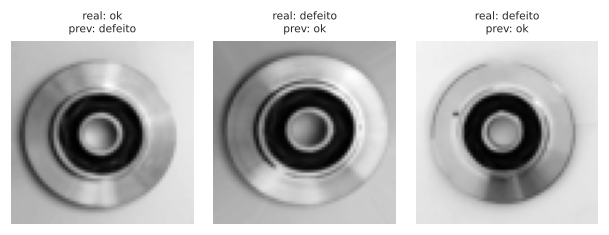

In [17]:
show_errors(cast_X_test, cast_y_test, cast_preds["CNN"], ["ok", "defeito"], "cast_cnn_erros.png")

**Discussão (Casting):** ver comentários nas Seções 10–11 e no relatório. Em resumo, a CNN aprende
filtros diretamente dos pixels e captura defeitos locais pequenos em qualquer posição da peça
(invariância a translação por convolução + pooling), enquanto os modelos clássicos dependem do
HOG+PCA, que resume a imagem em gradientes por célula e perde parte da informação fina.

---
# DATASET 3 — NEU Surface Defect Database
## Seção 6 — Análise exploratória (EDA)

Seis tipos de defeito superficial em aço laminado a quente, 300 imagens por classe, 200×200 px em escala
de cinza. A versão do Kaggle (fantacher) vem dividida em train/valid/test; aqui **juntamos todas as 1.800
imagens e refazemos uma divisão estratificada 70/15/15**, para ter um teste maior (270 imagens) e
estatisticamente mais confiável que os 72 da divisão original.

total: 1800 | resolução original: (200, 200) L


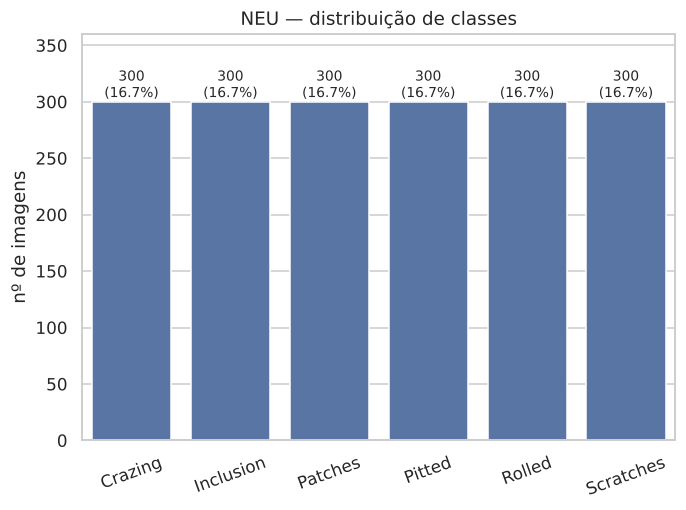

0    300
1    300
2    300
3    300
4    300
5    300
Name: count, dtype: int64

In [18]:
NEU_CLASSES = ["Crazing", "Inclusion", "Patches", "Pitted", "Rolled", "Scratches"]
neu_paths, neu_y = [], []
for c, cname in enumerate(NEU_CLASSES):
    ps = sorted(glob.glob(os.path.join(NEU_DIR, "*", cname, "*")))
    neu_paths += ps; neu_y += [c] * len(ps)
neu_y = np.array(neu_y)
print("total:", len(neu_paths), "| resolução original:", Image.open(neu_paths[0]).size, Image.open(neu_paths[0]).mode)
plot_class_distribution(neu_y, NEU_CLASSES, "NEU — distribuição de classes", "neu_dist.png")

Dataset **perfeitamente balanceado** (300 por classe): acurácia e F1 macro são diretamente comparáveis e
não há necessidade de ponderação de classes.

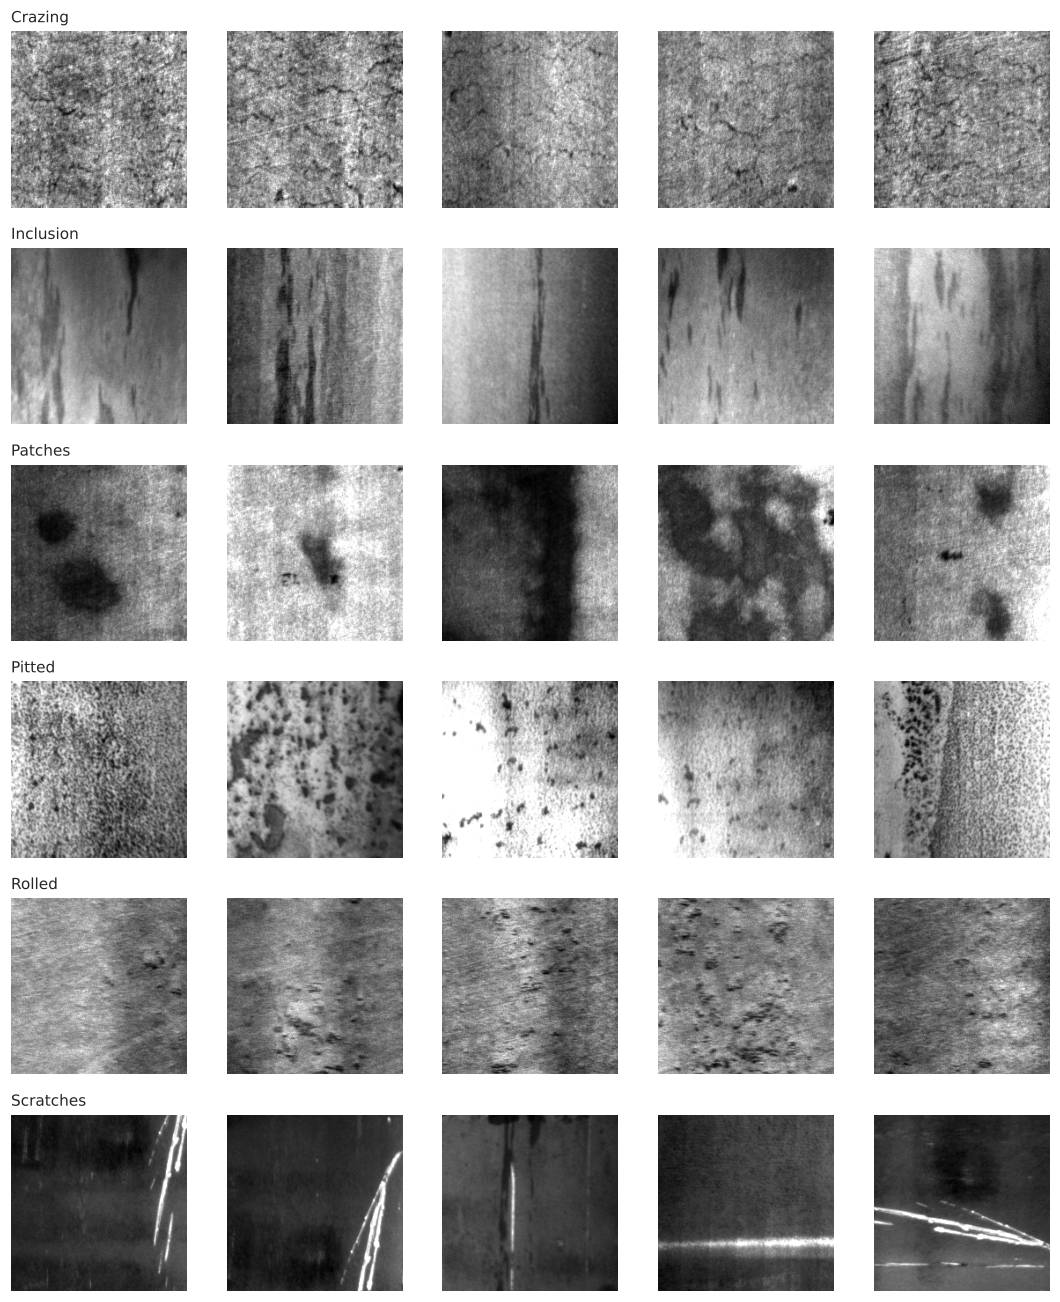

In [19]:
plot_samples(neu_paths, neu_y, NEU_CLASSES, "neu_amostras.png")

As classes são definidas por **textura**: *crazing* (rede fina de trincas), *inclusion* (manchas alongadas
escuras), *patches* (manchas grandes claras/escuras), *pitted surface* (pequenos poços), *rolled-in scale*
(carepa laminada, pontilhada) e *scratches* (riscos lineares). Há grande variação intra-classe de
brilho/contraste e similaridade visual entre *crazing*, *pitted* e *rolled-in scale*.

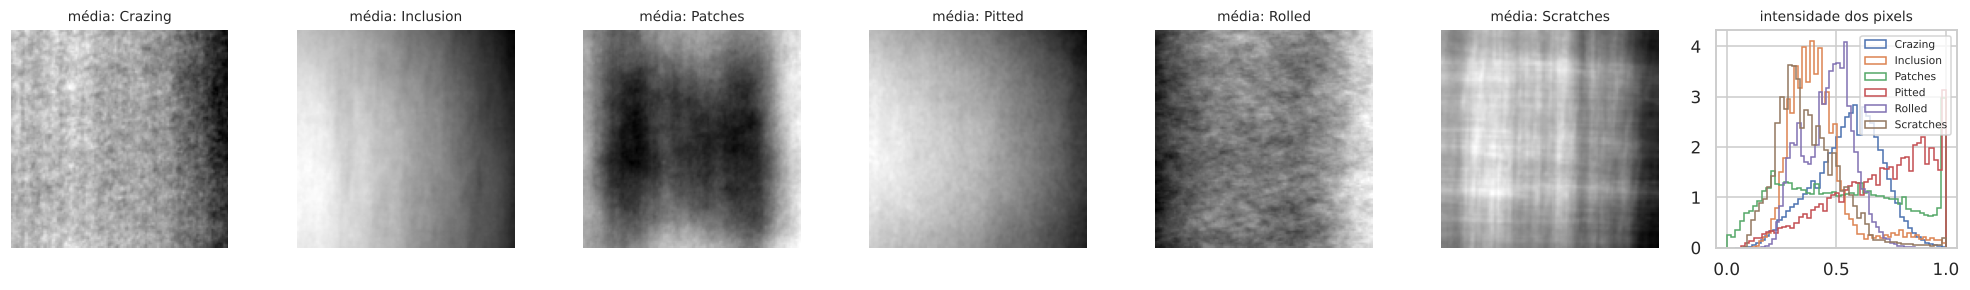

           média  desvio
Crazing    0.553   0.153
Inclusion  0.417   0.143
Patches    0.520   0.272
Pitted     0.693   0.221
Rolled     0.462   0.113
Scratches  0.373   0.145


In [20]:
neu_X = load_images(neu_paths, size=NEU_IMG_SIZE)
plot_mean_and_hist(neu_X, neu_y, NEU_CLASSES, "neu_media_hist.png")
print(pd.DataFrame({"média": [neu_X[neu_y == c].mean() for c in range(6)],
                    "desvio": [neu_X[neu_y == c].std() for c in range(6)]}, index=NEU_CLASSES).round(3))

Ao contrário do Casting, as classes têm brilho médio diferente (ex.: *crazing* e *rolled-in* mais escuras,
*patches* com maior variância), mas os histogramas se sobrepõem bastante — a informação discriminante
está na textura.

## Seção 7 — Pré-processamento
Mesmo protocolo do Casting (escala de cinza, pixels em [0,1], HOG → padronização → PCA(100) para os
clássicos, pixels para a CNN), com duas diferenças justificadas pela natureza de **textura** do NEU:
- **128×128 px** em vez de 64×64: reduzir 200→64 apaga a textura fina (trincas do *crazing*, poços do *pitted*).
- **HOG com células de 16×16 px** (2×2 células por bloco → 1.764 features, mesma dimensão do Casting): células
  maiores resumem a textura em regiões maiores e são mais estáveis. Num teste preliminar com SVM (CV 5 folds),
  a combinação 64 px/células 8 deu F1 ≈ 0,80, 64 px/células 16 ≈ 0,87 e 128 px/células 16 ≈ 0,92.

Split estratificado 70/15/15.
Como o dataset é pequeno (1.260 imagens de treino), a CNN usa **aumento de dados** (flips horizontais/
verticais e rotações de até ±36°) — defeitos de superfície não têm orientação preferencial, então essas
transformações preservam o rótulo.

treino: (1260, 128, 128) | validação: (270, 128, 128) | teste: (270, 128, 128)


HOG: (1530, 1764)


features,Flatten 32×32 + PCA,HOG + PCA
modelo,,
NB,0.6312,0.7812
RF,0.8072,0.8713
SVM (rbf),0.6992,0.8691


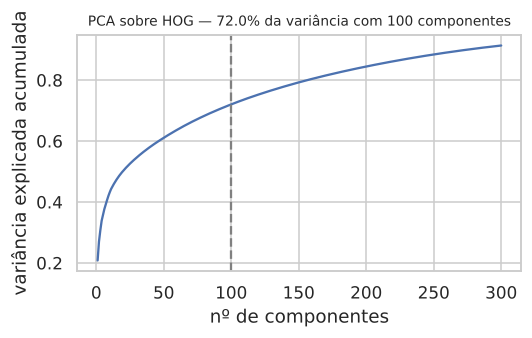

In [21]:
neu_X_trv, neu_X_test, neu_y_trv, neu_y_test = train_test_split(neu_X, neu_y, test_size=0.15, stratify=neu_y, random_state=SEED)
neu_X_tr, neu_X_val, neu_y_tr, neu_y_val = train_test_split(neu_X_trv, neu_y_trv, test_size=0.15 / 0.85,
                                                            stratify=neu_y_trv, random_state=SEED)
print("treino:", neu_X_tr.shape, "| validação:", neu_X_val.shape, "| teste:", neu_X_test.shape)

neu_F_trv = hog_features(neu_X_trv, ppc=16)
neu_F_test = hog_features(neu_X_test, ppc=16)
print("HOG:", neu_F_trv.shape)

neu_feat_cmp = compare_feature_sets({"Flatten 32×32 + PCA": flatten_features(neu_X_trv), "HOG + PCA": neu_F_trv},
                                    neu_y_trv, StratifiedKFold(3, shuffle=True, random_state=SEED))
display(neu_feat_cmp.round(4))
plot_pca_variance(neu_F_trv, "neu_pca.png")

## Seção 8 — Hiperparametrização e treinamento

In [22]:
neu_search_classic, neu_best_classic = cached("neu_classic", lambda: tune_classic(neu_F_trv, neu_y_trv, cv))

MLP  | GS F1=0.8583 (  8.7s) | Optuna F1=0.8724 ( 15.6s) -> usa Optuna: {'clf__hidden_layer_sizes': (128, 64), 'clf__alpha': 1.2087541473056957e-05, 'clf__learning_rate_init': 0.008706020878304856}


SVM  | GS F1=0.8973 (  4.3s) | Optuna F1=0.9017 ( 11.3s) -> usa Optuna: {'clf__C': 4.477934761483143, 'clf__gamma': 0.001870701309705171}


AD   | GS F1=0.7946 (  5.3s) | Optuna F1=0.7959 ( 10.9s) -> usa Optuna: {'clf__max_depth': 18, 'clf__min_samples_leaf': 12, 'clf__criterion': 'gini'}


RF   | GS F1=0.8730 ( 33.2s) | Optuna F1=0.8791 ( 93.5s) -> usa Optuna: {'clf__n_estimators': 300, 'clf__max_depth': 26, 'clf__max_features': 0.14035228220197152, 'clf__min_samples_leaf': 1}


NB   | GS F1=0.7879 (  2.3s) | Optuna F1=0.7879 (  4.0s) -> usa GridSearch: {'clf__var_smoothing': np.float64(1e-12)}


In [23]:
neu_Xc_tr, neu_Xc_val, neu_Xc_test = neu_X_tr[..., None], neu_X_val[..., None], neu_X_test[..., None]
neu_search_cnn, neu_best_cnn, neu_study_cnn = cached("neu_cnn", lambda: tune_cnn(
    neu_Xc_tr, neu_y_tr, neu_Xc_val, neu_y_val, n_classes=6, augment=True, epochs_search=30))

CNN | GS F1(val)=1.0000 (2802s) | Optuna F1(val)=0.9926 (3052s, 8 trials podados)
Melhor configuração da CNN: ('GridSearch', {'n_filters': 32, 'n_blocks': 3, 'dense_units': 128, 'dropout': 0.3, 'lr': 0.001})


,GS: F1 CV,GS: nº avaliações,GS: tempo (s),Optuna: F1 CV,Optuna: nº trials,Optuna: tempo (s)
modelo,,,,,,
MLP,0.8583,18,8.6554,0.8724,25,15.6433
SVM,0.8973,12,4.3471,0.9017,25,11.3472
AD,0.7946,24,5.3092,0.7959,25,10.8591
RF,0.8730,12,33.1539,0.8791,25,93.4911
NB,0.7879,11,2.2844,0.7879,12,3.9630
CNN,1.0000,8,2802.4638,0.9926,12,3052.4284


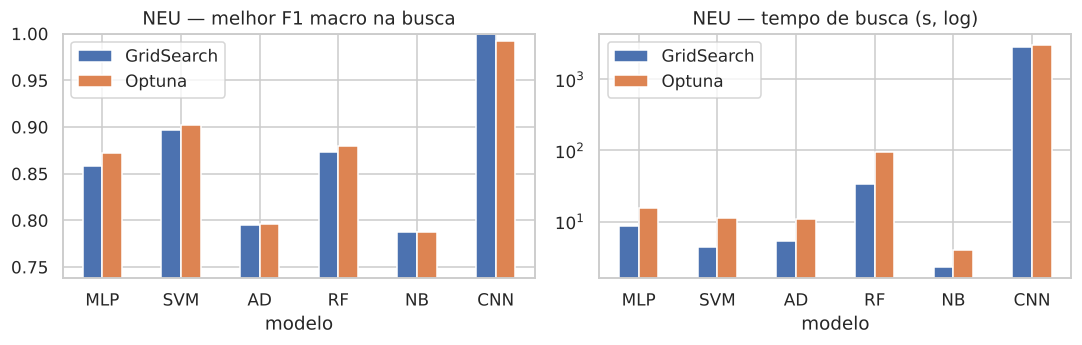

In [24]:
neu_search = pd.concat([neu_search_classic, neu_search_cnn])
display(neu_search.round(4))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.3))
neu_search[["GS: F1 CV", "Optuna: F1 CV"]].plot.bar(ax=ax[0], rot=0)
ax[0].set_ylim(max(0, neu_search[["GS: F1 CV", "Optuna: F1 CV"]].min().min() - 0.05), 1.0)
ax[0].set_title("NEU — melhor F1 macro na busca"); ax[0].legend(["GridSearch", "Optuna"])
neu_search[["GS: tempo (s)", "Optuna: tempo (s)"]].plot.bar(ax=ax[1], rot=0, logy=True)
ax[1].set_title("NEU — tempo de busca (s, log)"); ax[1].legend(["GridSearch", "Optuna"])
savefig("neu_gs_vs_optuna.png")

CNN final: 44 épocas, 708.8s, 305,062 parâmetros


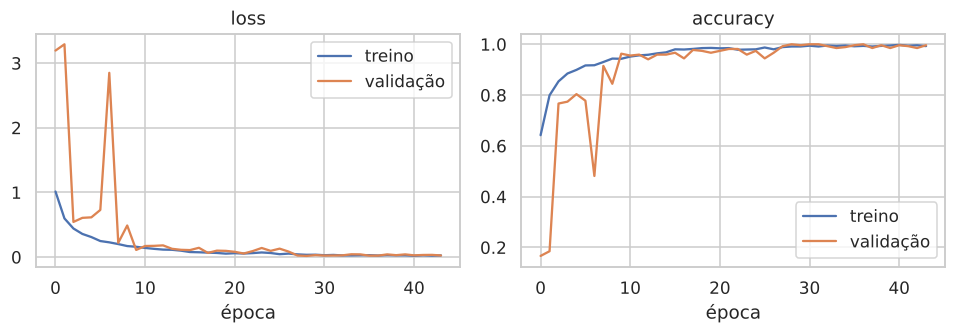

In [25]:
neu_preds, neu_times, neu_models = fit_final_classic(neu_best_classic, neu_F_trv, neu_y_trv, neu_F_test)
CNN_MAX_EPOCHS_BAK, CNN_MAX_EPOCHS = CNN_MAX_EPOCHS, 80   # dataset pequeno + aumento de dados: mais épocas
neu_cnn, neu_hist, neu_times["CNN"] = train_final_cnn(neu_best_cnn[1], neu_Xc_tr, neu_y_tr, neu_Xc_val, neu_y_val,
                                                      6, True, os.path.join(MODEL_DIR, "cnn_neu.keras"), patience=15)
CNN_MAX_EPOCHS = CNN_MAX_EPOCHS_BAK
neu_preds["CNN"] = neu_cnn.predict(neu_Xc_test, verbose=0).argmax(1)
plot_history(neu_hist, "neu_cnn_curvas.png")

## Seção 9 — Avaliação no conjunto de teste (270 imagens)

,Acurácia,Precisão (macro),Recall (macro),F1 (macro),Tempo de treino (s)
modelo,,,,,
CNN,0.9926,0.9928,0.9926,0.9926,708.7589
SVM,0.9222,0.9245,0.9222,0.9210,0.7668
MLP,0.8852,0.8908,0.8852,0.8859,0.6664
RF,0.8852,0.8851,0.8852,0.8838,1.5535
NB,0.8185,0.8362,0.8185,0.8156,0.7464
AD,0.7815,0.7862,0.7815,0.7815,1.1761


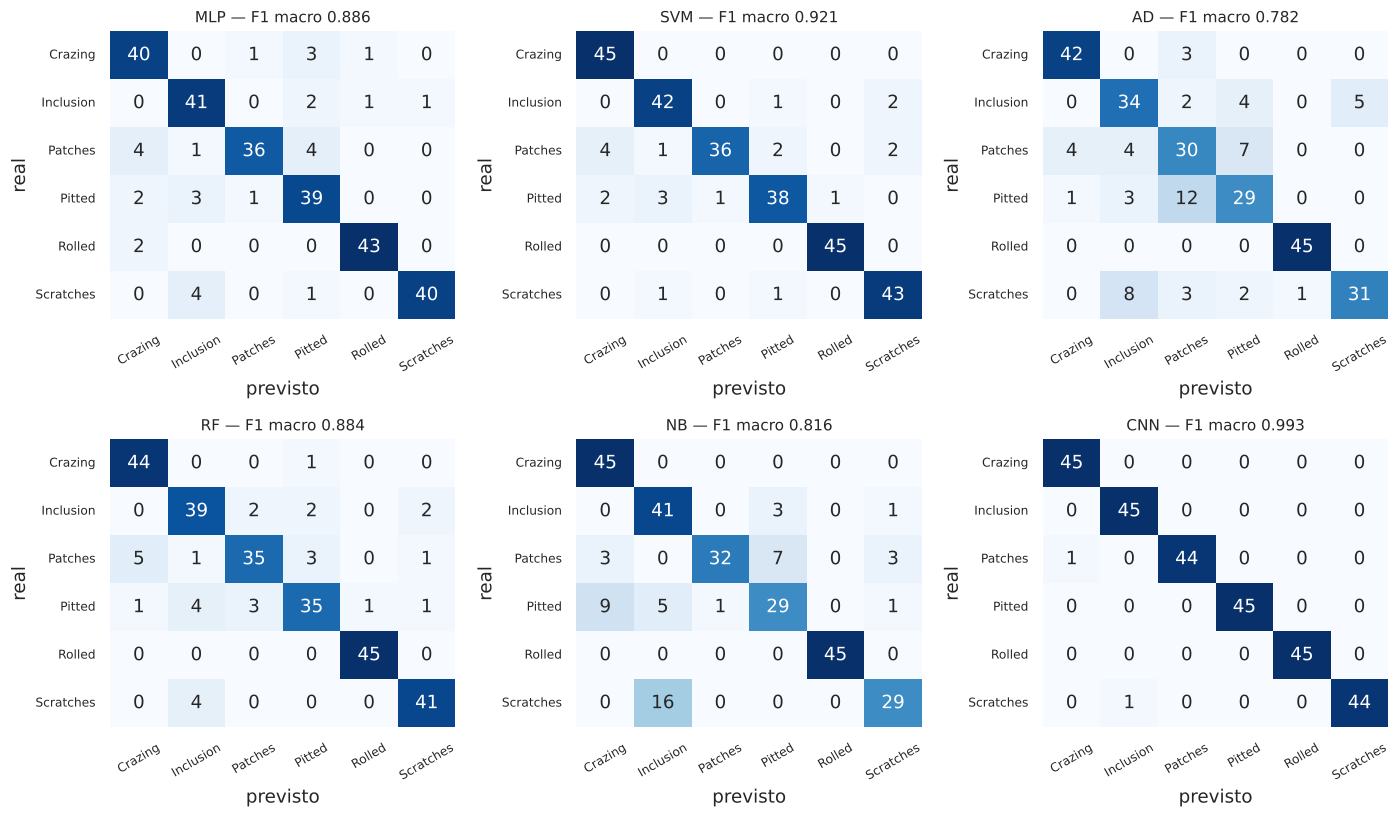

In [26]:
neu_metrics = metrics_table(neu_y_test, neu_preds, neu_times)
RESULTS["NEU"] = neu_metrics
display(neu_metrics.round(4).sort_values("F1 (macro)", ascending=False))
plot_confusions(neu_y_test, neu_preds, NEU_CLASSES, "neu_confusao.png")

### F1-Score por classe (pedido na nota do Dataset 3)

,Crazing,Inclusion,Patches,Pitted,Rolled,Scratches
MLP,0.860,0.872,0.867,0.830,0.956,0.930
SVM,0.938,0.913,0.878,0.874,0.989,0.935
AD,0.913,0.723,0.632,0.667,0.989,0.765
RF,0.926,0.839,0.824,0.814,0.989,0.911
NB,0.882,0.766,0.821,0.690,1.000,0.734
CNN,0.989,0.989,0.989,1.000,1.000,0.989


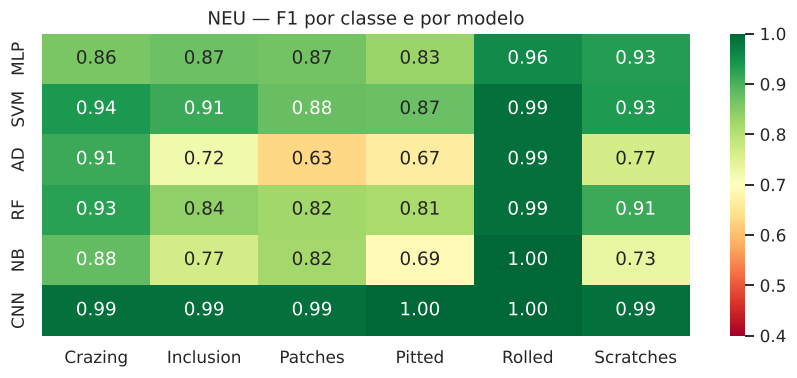

              precision    recall  f1-score   support

     Crazing      0.978     1.000     0.989        45
   Inclusion      0.978     1.000     0.989        45
     Patches      1.000     0.978     0.989        45
      Pitted      1.000     1.000     1.000        45
      Rolled      1.000     1.000     1.000        45
   Scratches      1.000     0.978     0.989        45

    accuracy                          0.993       270
   macro avg      0.993     0.993     0.993       270
weighted avg      0.993     0.993     0.993       270



In [27]:
neu_f1c = per_class_f1(neu_y_test, neu_preds, NEU_CLASSES)
display(neu_f1c.round(3))
plt.figure(figsize=(8, 3.6))
sns.heatmap(neu_f1c, annot=True, fmt=".2f", cmap="RdYlGn", vmin=0.4, vmax=1.0)
plt.title("NEU — F1 por classe e por modelo")
savefig("neu_f1_por_classe.png")
print(classification_report(neu_y_test, neu_preds["CNN"], target_names=NEU_CLASSES, digits=3))

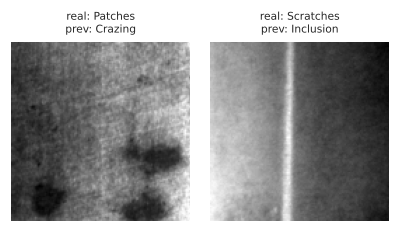

In [28]:
show_errors(neu_X_test, neu_y_test, neu_preds["CNN"], NEU_CLASSES, "neu_cnn_erros.png")

---
## Seção 10 — Comparação cruzada entre modelos e datasets

Acurácia  Precisão (macro)  Recall (macro)  F1 (macro)  \
dataset modelo                                                           
Casting MLP       0.9818            0.9764          0.9857      0.9806   
        SVM       0.9916            0.9895          0.9926      0.9910   
        AD        0.8615            0.8488          0.8642      0.8544   
        RF        0.9734            0.9725          0.9702      0.9713   
        NB        0.8448            0.8350          0.8574      0.8394   
        CNN       0.9958            0.9951          0.9959      0.9955   
NEU     MLP       0.8852            0.8908          0.8852      0.8859   
        SVM       0.9222            0.9245          0.9222      0.9210   
        AD        0.7815            0.7862          0.7815      0.7815   
        RF        0.8852            0.8851          0.8852      0.8838   
        NB        0.8185            0.8362          0.8185      0.8156   
        CNN       0.9926            0.9928          0.9926      0.9926   

                Tempo de treino (s)  
dataset modelo                       
Casting MLP                  1.9899  
        SVM                  2.2944  
        AD                   1.7905  
        RF                   5.4906  
        NB                   0.9793  
        CNN                314.0946  
NEU     MLP                  0.6664  
        SVM                  0.7668  
        AD                   1.1761  
        RF                   1.5535  
        NB                   0.7464  
        CNN                708.7589

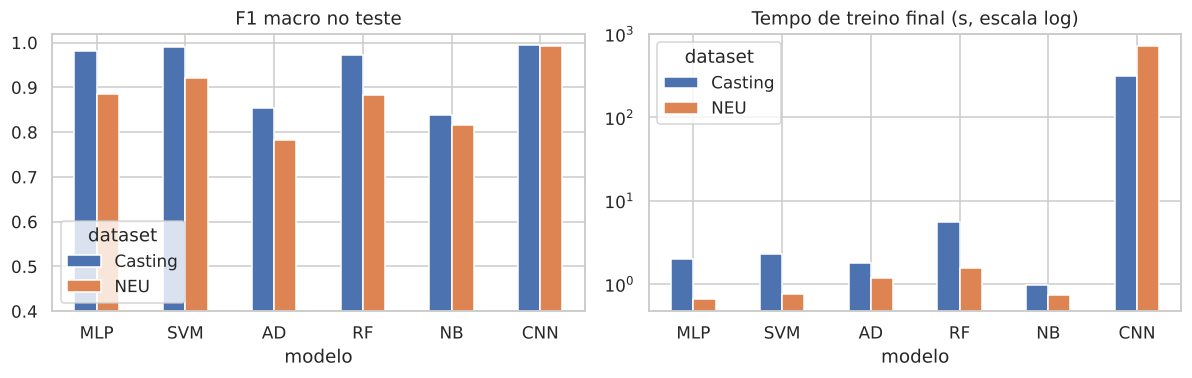

GS: F1 CV  GS: nº avaliações  GS: tempo (s)  Optuna: F1 CV  \
dataset modelo                                                               
Casting MLP        0.9804                 18        25.5436         0.9815   
        SVM        0.9905                 12        29.7949         0.9920   
        AD         0.8456                 24        25.7527         0.8456   
        RF         0.9545                 12       165.8651         0.9547   
        NB         0.8219                 11         7.6903         0.8219   
        CNN        0.9990                  8      2522.6707         0.9990   
NEU     MLP        0.8583                 18         8.6554         0.8724   
        SVM        0.8973                 12         4.3471         0.9017   
        AD         0.7946                 24         5.3092         0.7959   
        RF         0.8730                 12        33.1539         0.8791   
        NB         0.7879                 11         2.2844         0.7879   
        CNN        1.0000                  8      2802.4638         0.9926   

                Optuna: nº trials  Optuna: tempo (s)  
dataset modelo                                        
Casting MLP                    25            56.6867  
        SVM                    25            88.7763  
        AD                     25            43.2280  
        RF                     25           449.4141  
        NB                     12            12.1979  
        CNN                    12          3444.9537  
NEU     MLP                    25            15.6433  
        SVM                    25            11.3472  
        AD                     25            10.8591  
        RF                     25            93.4911  
        NB                     12             3.9630  
        CNN                    12          3052.4284

In [29]:
comp = pd.concat({k: v for k, v in RESULTS.items()}, names=["dataset"])
display(comp.round(4))
comp.round(4).to_csv("resultados_cnn_classicos.csv")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
comp["F1 (macro)"].unstack(0).loc[["MLP", "SVM", "AD", "RF", "NB", "CNN"]].plot.bar(ax=ax[0], rot=0)
ax[0].set_ylim(0.4, 1.02); ax[0].set_title("F1 macro no teste"); ax[0].legend(title="dataset", loc="lower left")
comp["Tempo de treino (s)"].unstack(0).loc[["MLP", "SVM", "AD", "RF", "NB", "CNN"]].plot.bar(ax=ax[1], rot=0, logy=True)
ax[1].set_title("Tempo de treino final (s, escala log)"); ax[1].legend(title="dataset")
savefig("comparacao_cruzada.png")

search_all = pd.concat({"Casting": cast_search, "NEU": neu_search}, names=["dataset"])
search_all.round(4).to_csv("busca_gs_vs_optuna.csv")
display(search_all.round(4))

## Seção 11 — Conclusões

| F1 macro (teste) | MLP | SVM | AD | RF | NB | **CNN** |
|---|---|---|---|---|---|---|
| Casting (715 imagens) | 0,981 | 0,991 | 0,854 | 0,971 | 0,839 | **0,996** |
| NEU (270 imagens) | 0,886 | 0,921 | 0,782 | 0,884 | 0,816 | **0,993** |

1. **A CNN foi o melhor modelo nos dois datasets.** Ela aprende filtros locais diretamente dos pixels, que é exatamente o que os dois problemas exigem: defeitos pequenos em qualquer posição da peça (Casting) e padrões de textura (NEU). Os modelos clássicos dependem de uma representação fixa (HOG + PCA), que resume a imagem em histogramas de gradiente e descarta parte da informação fina.
2. **A vantagem da CNN é muito maior no NEU** (+7 pontos de F1 sobre o SVM) do que no Casting (+0,5 ponto). No Casting, o HOG já captura bem as bordas irregulares dos defeitos, e o SVM chega a 0,991. No NEU, as classes diferem por texturas sutis que o HOG não distingue bem: as confusões dos clássicos se concentram entre *patches*, *pitted*, *crazing* e *inclusion*. Já a CNN, com aumento de dados, erra só 2 de 270 imagens.
3. **Entre os clássicos**, a ordem foi a mesma nos dois datasets: SVM > MLP ≈ RF > NB ≈ AD. A árvore única tem alta variância em features contínuas de alta dimensão. O NB supõe que as componentes são independentes e gaussianas, o que não se verifica aqui. *Rolled-in scale* é fácil para todos os modelos (F1 ≥ 0,96), porque tem uma textura pontilhada muito característica.
4. **Casting e falsos negativos:** a CNN aprovou só 2 das 453 peças defeituosas, e o SVM aprovou 5. NB e AD deixariam passar 86 e 66, o que é inaceitável em controle de qualidade. Ressalva: o dataset contém versões aumentadas das mesmas peças, então pode haver peças "parentes" em treino e teste, e o desempenho real tende a ser um pouco menor.
5. **GridSearch × Optuna:** nos clássicos, o Optuna igualou ou superou ligeiramente o GridSearch em todos os 10 casos (melhor em 7, empate em 3; ganho máximo de 1,4 ponto de F1, no MLP do NEU), porque explora valores contínuos fora da grade (por exemplo, C = 553 no SVM do Casting). Em geral, porém, levou mais tempo (25 trials contra 11 a 24 combinações). Na CNN, as duas buscas chegaram a F1 de validação ≥ 0,99. O pruner Hyperband interrompeu 4 (Casting) e 8 (NEU) dos 12 trials, mas o custo continuou dominado pelo treino da rede.
6. **Custo:** a CNN levou de 5 a 12 minutos para treinar em CPU, contra 1 a 6 segundos dos clássicos. Em uma linha de inspeção real, porém, o custo de treino é pago uma vez e a inferência da CNN é rápida.
7. **Lição prática:** na primeira execução, a CNN do NEU ficou "presa" (F1 ≈ 0,13). As médias móveis da BatchNormalization (momentum padrão 0,99) ainda não tinham convergido, e o EarlyStopping restaurou os pesos da 1ª época. Usar `momentum=0.9` e `start_from_epoch=5` resolveu o problema.